<a href="https://colab.research.google.com/github/NatShed/-/blob/main/Final_project_CovidXray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Работа выполнена студентами Любов Кирилл и Щедрина Наталья, группа БАС-2021  
Выбранный датасет для финального проекта - https://www.kaggle.com/datasets/ahemateja19bec1025/covid-xray-dataset?resource=download

# Подготовка окружения


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
import torchvision.transforms.functional as TF
from torchvision.datasets import ImageFolder

import torchattacks
from torchmetrics import Accuracy, Precision, Recall, F1Score
from torchmetrics.classification import MulticlassConfusionMatrix

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(333)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")
print(f"PyTorch версия: {torch.__version__}")

Устройство: cuda
PyTorch версия: 2.14.1+cu130


# Загрузка датасета Covid Xray

In [ ]:
from google.colab import files

print("Загрузите файл kaggle.json (https://www.kaggle.com/account):")
uploaded = files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# --force, чтобы гарантированно перекачать архив
!kaggle datasets download -d ahemateja19bec1025/covid-xray-dataset --force

# -o, чтобы не спрашивать про замену файлов при повторном запуске
!unzip -o -q covid-xray-dataset.zip -d /content/covid_xray

print("\nСодержимое директории:")
!find /content/covid_xray -maxdepth 3 -type d | head -30

Загрузите файл kaggle.json (https://www.kaggle.com/account):


Saving covid-xray-dataset-metadata.json to covid-xray-dataset-metadata (2).json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/ahemateja19bec1025/covid-xray-dataset
License(s): CC0-1.0
100% 1.04G/1.04G [00:18<00:00, 59.1MB/s]


Содержимое директории:
/content/covid_xray
/content/covid_xray/DATA
/content/covid_xray/DATA/DATA
/content/covid_xray/DATA/DATA/0
/content/covid_xray/DATA/DATA/1


# Подготовка данных к обучению

In [ ]:
from collections import Counter

DATA_ROOT = "/content/covid_xray/DATA/DATA"
assert os.path.isdir(DATA_ROOT), f"Путь не найден: {DATA_ROOT}"

IMG_SIZE = 224
BATCH_SIZE = 32

baseline_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = ImageFolder(root=DATA_ROOT, transform=baseline_transform)
class_names = full_dataset.classes
num_classes = len(class_names)
print(f"Всего изображений: {len(full_dataset)}")
print(f"Классы: {class_names}  (0 = нет ковида, 1 = есть ковид)")

labels_all = [label for _, label in full_dataset.samples]
label_counts = Counter(labels_all)
print("\nРаспределение по классам:")
for cls_idx in sorted(label_counts.keys()):
    count = label_counts[cls_idx]
    pct = 100 * count / len(full_dataset)
    print(f"  Класс {cls_idx} ('{class_names[cls_idx]}'): {count} ({pct:.1f}%)")

total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("\nРазбиение выборки:")
print(f"  Train: {len(train_dataset)}")
print(f"  Val:   {len(val_dataset)}")
print(f"  Test:  {len(test_dataset)}")


def split_class_counts(subset, name):
    subset_labels = [full_dataset.samples[i][1] for i in subset.indices]
    cnt = Counter(subset_labels)
    print(f"  {name}: " + ", ".join(
        f"class {c} = {cnt.get(c, 0)}" for c in range(num_classes)))


print("\nБаланс классов:")
split_class_counts(train_dataset, "Train")
split_class_counts(val_dataset, "Val")
split_class_counts(test_dataset, "Test")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"\nБатчей: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")

images, labels_batch = next(iter(train_loader))
print(f"\nФорма батча: {images.shape}, пример меток: {labels_batch[:8].tolist()}")

Всего изображений: 3091
Классы: ['0', '1']  (0 = нет ковида, 1 = есть ковид)

Распределение по классам:
  Класс 0 ('0'): 1301 (42.1%)
  Класс 1 ('1'): 1790 (57.9%)

Разбиение выборки:
  Train: 2163
  Val:   463
  Test:  465

Баланс классов:
  Train: class 0 = 909, class 1 = 1254
  Val: class 0 = 209, class 1 = 254
  Test: class 0 = 183, class 1 = 282

Батчей: train=68, val=15, test=15

Форма батча: torch.Size([32, 3, 224, 224]), пример меток: [1, 1, 1, 1, 1, 0, 0, 1]


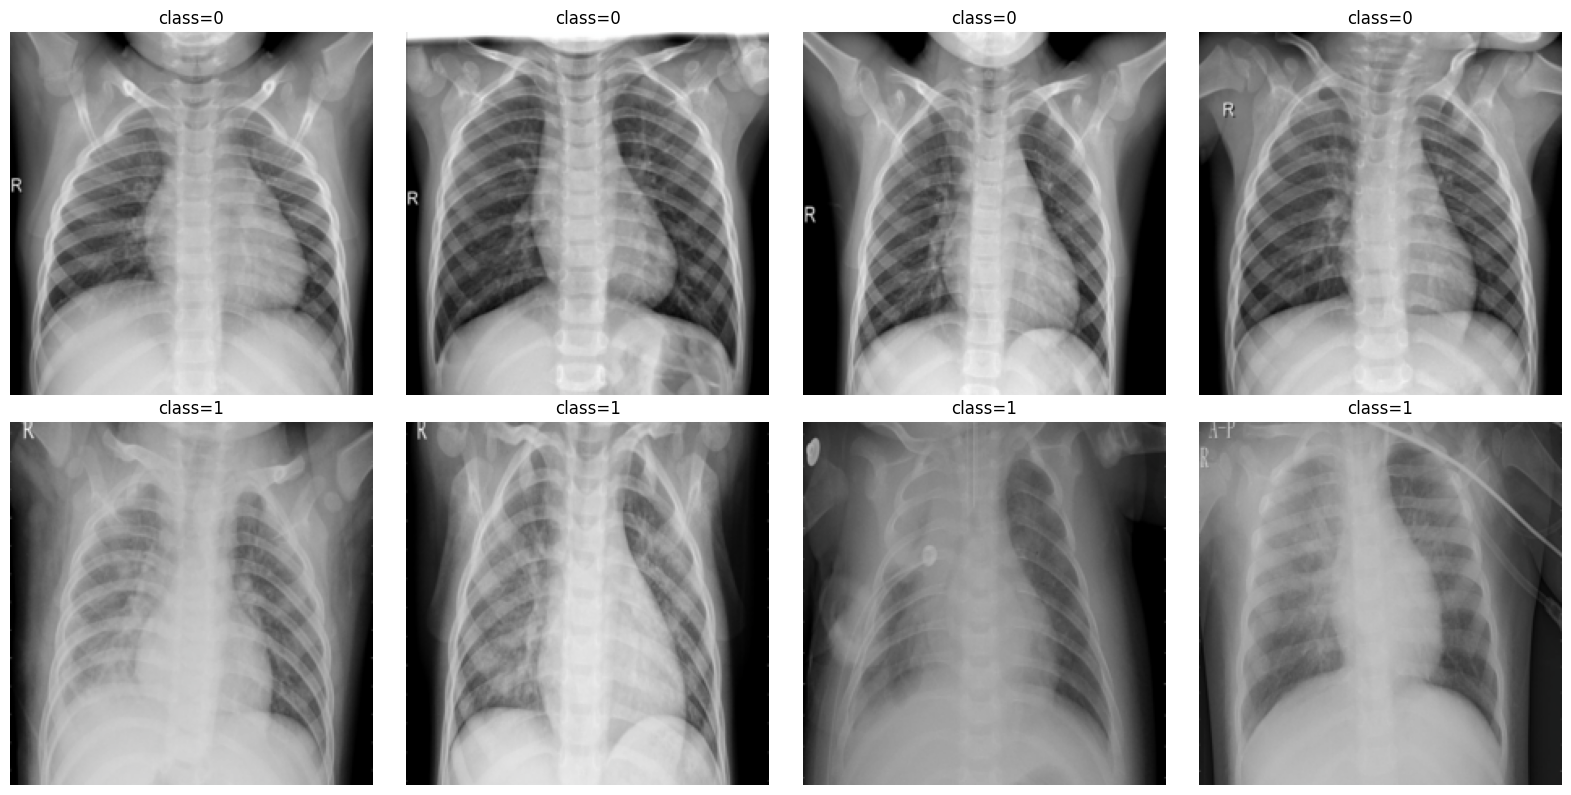

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

class_indices = {i: [] for i in range(num_classes)}
for idx, (_, label) in enumerate(full_dataset.samples):
    class_indices[label].append(idx)

plot_idx = 0
for cls_id in range(num_classes):
    for _ in range(min(4, len(class_indices[cls_id]))):
        idx = random.choice(class_indices[cls_id])
        img, label = full_dataset[idx]
        img_show = img.permute(1, 2, 0).numpy()
        img_show = np.clip(img_show * np.array([0.229, 0.224, 0.225])
                           + np.array([0.485, 0.456, 0.406]), 0, 1)
        axes[plot_idx].imshow(img_show)
        axes[plot_idx].set_title(f"class={class_names[label]}")
        axes[plot_idx].axis('off')
        plot_idx += 1
        if plot_idx >= 8:
            break
    if plot_idx >= 8:
        break

plt.tight_layout()
plt.show()

# Baseline модель

In [ ]:
def create_baseline_model(num_classes, device):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

baseline_model = create_baseline_model(num_classes, device)

total_params = sum(p.numel() for p in baseline_model.parameters())
trainable_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"Всего параметров: {total_params:,}")
print(f"Обучаемых параметров: {trainable_params:,}")

criterion = nn.CrossEntropyLoss()
optimizer_baseline = optim.Adam(baseline_model.parameters(), lr=0.001)

Всего параметров: 11,177,538
Обучаемых параметров: 11,177,538


In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    return running_loss / total, correct / total


def evaluate(model, loader, criterion, device, return_predictions=False):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    preds_t = torch.tensor(all_preds)
    labels_t = torch.tensor(all_labels)

    precision = Precision(task="multiclass", num_classes=num_classes, average='macro')
    recall = Recall(task="multiclass", num_classes=num_classes, average='macro')
    f1 = F1Score(task="multiclass", num_classes=num_classes, average='macro')
    precision.update(preds_t, labels_t)
    recall.update(preds_t, labels_t)
    f1.update(preds_t, labels_t)

    result = {
        'loss': running_loss / total,
        'accuracy': correct / total,
        'precision': precision.compute().item(),
        'recall': recall.compute().item(),
        'f1': f1.compute().item(),
    }
    if return_predictions:
        result['preds'] = np.array(all_preds)
        result['labels'] = np.array(all_labels)
    return result


def evaluate_under_attack(model, attack, loader, device, return_predictions=False):
    """Атака untargeted: передаём истинные метки."""
    model.eval()
    correct = 0
    total = 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        adv_images = attack(images, labels)
        with torch.no_grad():
            outputs = model(adv_images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    result = {'accuracy': correct / total}
    if return_predictions:
        result['preds'] = np.array(all_preds)
        result['labels'] = np.array(all_labels)
    return result


def plot_confusion_matrix(preds, labels, title, class_names):
    cm = MulticlassConfusionMatrix(num_classes=num_classes)
    cm_tensor = cm(torch.tensor(preds), torch.tensor(labels)).numpy()
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_tensor, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return cm_tensor

In [ ]:
EPOCHS_BASELINE = 10
best_val_acc = 0.0
baseline_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("=" * 60)
print("ОБУЧЕНИЕ BASELINE (10 эпох, все параметры обучаемы)")
print("=" * 60)

for epoch in range(EPOCHS_BASELINE):
    train_loss, train_acc = train_epoch(
        baseline_model, train_loader, criterion, optimizer_baseline, device)
    val_metrics = evaluate(baseline_model, val_loader, criterion, device)

    baseline_history['train_loss'].append(train_loss)
    baseline_history['train_acc'].append(train_acc)
    baseline_history['val_loss'].append(val_metrics['loss'])
    baseline_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{EPOCHS_BASELINE}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val P: {val_metrics['precision']:.4f} | R: {val_metrics['recall']:.4f} | F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_val_acc:
        best_val_acc = val_metrics['accuracy']
        torch.save(baseline_model.state_dict(), 'baseline_best.pth')
        print(f"  → Сохранена лучшая модель (val_acc={best_val_acc:.4f})")
    print()

baseline_model.load_state_dict(torch.load('baseline_best.pth'))
print(f"Лучшая Baseline Val Accuracy: {best_val_acc:.4f}")

ОБУЧЕНИЕ BASELINE (10 эпох, все параметры обучаемы)
Epoch 1/10
  Train Loss: 0.1572 | Train Acc: 0.9417
  Val Loss: 0.0967 | Val Acc: 0.9611
  Val P: 0.9599 | R: 0.9624 | F1: 0.9609
  → Сохранена лучшая модель (val_acc=0.9611)

Epoch 2/10
  Train Loss: 0.0474 | Train Acc: 0.9815
  Val Loss: 0.0659 | Val Acc: 0.9741
  Val P: 0.9738 | R: 0.9738 | F1: 0.9738
  → Сохранена лучшая модель (val_acc=0.9741)

Epoch 3/10
  Train Loss: 0.0704 | Train Acc: 0.9755
  Val Loss: 0.2028 | Val Acc: 0.9546
  Val P: 0.9540 | R: 0.9582 | F1: 0.9545

Epoch 4/10
  Train Loss: 0.0549 | Train Acc: 0.9797
  Val Loss: 0.2517 | Val Acc: 0.9158
  Val P: 0.9334 | R: 0.9067 | F1: 0.9129

Epoch 5/10
  Train Loss: 0.0390 | Train Acc: 0.9861
  Val Loss: 0.0872 | Val Acc: 0.9719
  Val P: 0.9708 | R: 0.9731 | F1: 0.9717

Epoch 6/10
  Train Loss: 0.0164 | Train Acc: 0.9935
  Val Loss: 0.0815 | Val Acc: 0.9784
  Val P: 0.9782 | R: 0.9782 | F1: 0.9782
  → Сохранена лучшая модель (val_acc=0.9784)

Epoch 7/10
  Train Loss: 0.

# Оценка baseline модели на тестовой выборке

BASELINE — ЧИСТЫЕ ДАННЫЕ
Accuracy:  0.9785
Precision: 0.9775
Recall:    0.9775
F1-Score:  0.9775
Loss:      0.0509


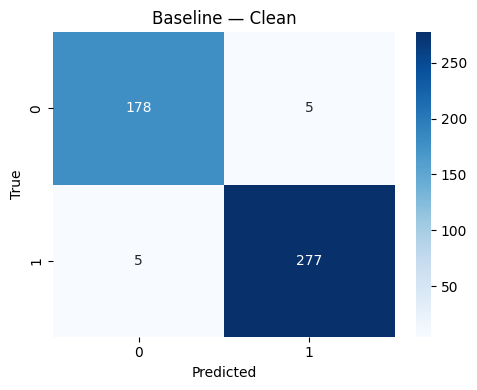


Baseline — FGSM Accuracy: 0.6065


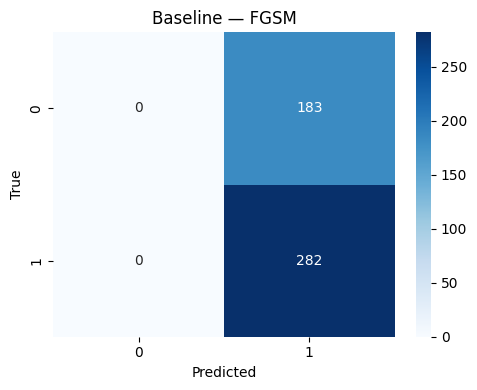

Baseline — PGD Accuracy: 0.2882


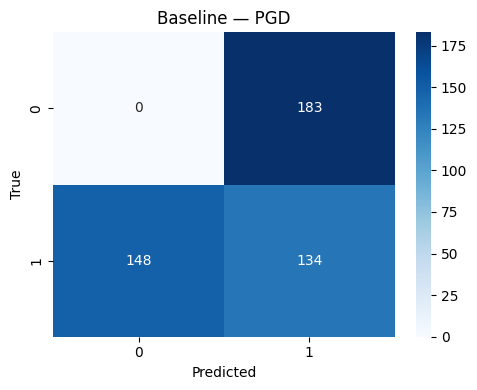

array([[  0, 183],
       [148, 134]])

In [ ]:
test_metrics_baseline = evaluate(
    baseline_model, test_loader, criterion, device, return_predictions=True)

print("=" * 60)
print("BASELINE — ЧИСТЫЕ ДАННЫЕ")
print("=" * 60)
print(f"Accuracy:  {test_metrics_baseline['accuracy']:.4f}")
print(f"Precision: {test_metrics_baseline['precision']:.4f}")
print(f"Recall:    {test_metrics_baseline['recall']:.4f}")
print(f"F1-Score:  {test_metrics_baseline['f1']:.4f}")
print(f"Loss:      {test_metrics_baseline['loss']:.4f}")

plot_confusion_matrix(test_metrics_baseline['preds'], test_metrics_baseline['labels'],
                      'Baseline — Clean', class_names)

# FGSM
fgsm_baseline = torchattacks.FGSM(baseline_model, eps=8/255)
baseline_fgsm = evaluate_under_attack(
    baseline_model, fgsm_baseline, test_loader, device, return_predictions=True)
baseline_fgsm_acc = baseline_fgsm['accuracy']
print(f"\nBaseline — FGSM Accuracy: {baseline_fgsm_acc:.4f}")
plot_confusion_matrix(baseline_fgsm['preds'], baseline_fgsm['labels'],
                      'Baseline — FGSM', class_names)

# PGD
pgd_baseline = torchattacks.PGD(baseline_model, eps=8/255, alpha=2/255, steps=10)
baseline_pgd = evaluate_under_attack(
    baseline_model, pgd_baseline, test_loader, device, return_predictions=True)
baseline_pgd_acc = baseline_pgd['accuracy']
print(f"Baseline — PGD Accuracy: {baseline_pgd_acc:.4f}")
plot_confusion_matrix(baseline_pgd['preds'], baseline_pgd['labels'],
                      'Baseline — PGD', class_names)

# Подготовка и обучение защищенной модели

In [ ]:
class RobustAugDataset(Dataset):
    def __init__(self, base_dataset, img_size=224,
                 rotate_angles=(-30, -15, 0, 15, 30),
                 noise_stds=(0.0, 0.0, 0.05, 0.1),
                 p_rotate=0.5, p_noise=0.5):
        self.base_dataset = base_dataset
        self.img_size = img_size
        self.rotate_angles = rotate_angles
        self.noise_stds = noise_stds
        self.p_rotate = p_rotate
        self.p_noise = p_noise
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        real_idx = self.base_dataset.indices[idx]
        img_path, label = self.base_dataset.dataset.samples[real_idx]
        img = Image.open(img_path).convert("RGB")
        img = img.resize((self.img_size, self.img_size))
        if random.random() < self.p_rotate:
            angle = random.choice(self.rotate_angles)
            img = TF.rotate(img, angle)
        img_t = TF.to_tensor(img)
        if random.random() < self.p_noise:
            std = random.choice(self.noise_stds)
            if std > 0:
                img_t = torch.clamp(img_t + torch.randn_like(img_t) * std, 0.0, 1.0)
        img_t = (img_t - self.mean) / self.std
        return img_t, label


robust_aug_train = RobustAugDataset(
    train_dataset, img_size=IMG_SIZE,
    rotate_angles=(-30, -15, 0, 15, 30),
    noise_stds=(0.0, 0.05, 0.1, 0.15),
    p_rotate=0.5, p_noise=0.5,
)
robust_aug_loader = DataLoader(robust_aug_train, batch_size=BATCH_SIZE,
                                shuffle=True, num_workers=2)

print(f"Датасет для дообучения: {len(robust_aug_train)} примеров, "
      f"{len(robust_aug_loader)} батчей")
print(f"Аугментации: повороты {robust_aug_train.rotate_angles}, "
      f"шум std {robust_aug_train.noise_stds}")

Датасет для дообучения: 2163 примеров, 68 батчей
Аугментации: повороты (-30, -15, 0, 15, 30), шум std (0.0, 0.05, 0.1, 0.15)


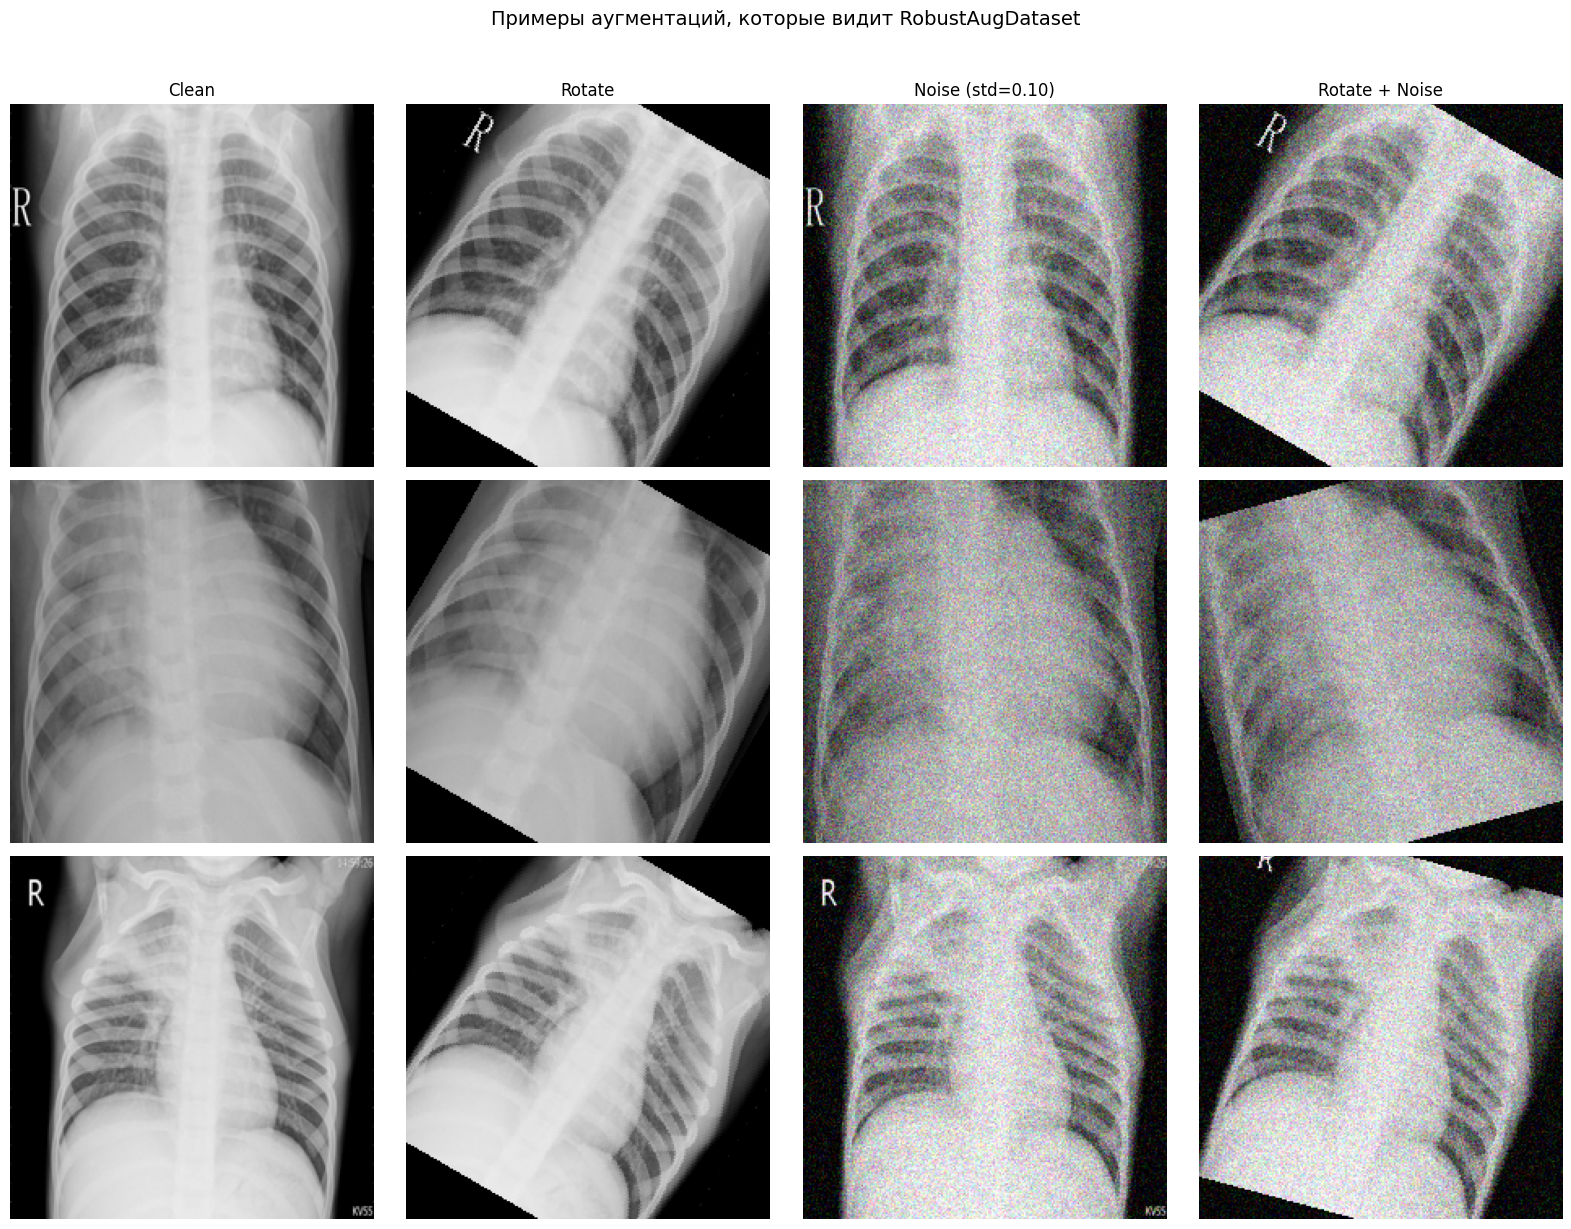

In [ ]:
# Денормализация для отображения
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def denorm(img_t):
    """[C,H,W] нормализованный тензор -> numpy [H,W,C] в [0,1]."""
    x = img_t.cpu() * _STD + _MEAN
    return np.clip(x.permute(1, 2, 0).numpy(), 0, 1)


def load_raw(idx):
    """Достаём исходное изображение из underlying ImageFolder (без трансформаций)."""
    real_idx = train_dataset.indices[idx]
    img_path, label = train_dataset.dataset.samples[real_idx]
    img = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    return img, label


# Фиксируем seed, чтобы картинка была воспроизводимой
random.seed(7)

# 3 случайных примера из train
sample_idx = random.sample(range(len(train_dataset)), 3)

scenarios = ["Clean", "Rotate", "Noise (std=0.10)", "Rotate + Noise"]

fig, axes = plt.subplots(len(sample_idx), len(scenarios),
                          figsize=(4 * len(scenarios), 4 * len(sample_idx)))
if len(sample_idx) == 1:
    axes = axes.reshape(1, -1)

for row, idx in enumerate(sample_idx):
    img_raw, label = load_raw(idx)
    cls_name = class_names[label]

    for col, scenario in enumerate(scenarios):
        img = img_raw.copy()

        if scenario in ("Rotate", "Rotate + Noise"):
            # случайный ненулевой угол
            angle = random.choice([a for a in (-30, -15, 15, 30)])
            img = TF.rotate(img, angle)

        img_t = TF.to_tensor(img)  # [C,H,W], значения в [0,1]

        if scenario in ("Noise (std=0.10)", "Rotate + Noise"):
            std = 0.10
            noise = torch.randn_like(img_t) * std
            img_t = torch.clamp(img_t + noise, 0.0, 1.0)

        img_t = (img_t - _MEAN) / _STD
        img_show = denorm(img_t)

        axes[row, col].imshow(img_show)
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(scenario, fontsize=12)
        if col == 0:
            axes[row, col].set_ylabel(f"class={cls_name}", fontsize=12)

plt.suptitle("Примеры аугментаций, которые видит RobustAugDataset",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
def create_robust_model(num_classes, device):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)


robust_model = create_robust_model(num_classes, device)
optimizer_robust = optim.Adam(robust_model.parameters(), lr=0.001)

ADV_EPS = 8 / 255
ADV_ALPHA = 2 / 255
ADV_STEPS = 7

print("Защищённая модель создана")
print(f"Adversarial training: eps={ADV_EPS:.4f}, alpha={ADV_ALPHA:.4f}, steps={ADV_STEPS}")

Защищённая модель создана
Adversarial training: eps=0.0314, alpha=0.0078, steps=7


In [ ]:
def adversarial_train_epoch(model, loader, criterion, optimizer, device,
                            pgd_attack, fgsm_attack):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # Генерируем adv-примеры в eval-режиме (атака не должна видеть BN-статистики обучения)
        model.eval()
        adv_pgd = pgd_attack(images, labels)
        adv_fgsm = fgsm_attack(images, labels)
        model.train()

        optimizer.zero_grad()

        outputs_clean = model(images)
        loss_clean = criterion(outputs_clean, labels)

        outputs_pgd = model(adv_pgd)
        loss_pgd = criterion(outputs_pgd, labels)

        outputs_fgsm = model(adv_fgsm)
        loss_fgsm = criterion(outputs_fgsm, labels)

        loss = (loss_clean + loss_pgd + loss_fgsm) / 3.0
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs_clean.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, correct / total


EPOCHS_ROBUST = 5
best_robust_val_acc = 0.0
robust_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

pgd_train = torchattacks.PGD(robust_model, eps=ADV_EPS, alpha=ADV_ALPHA, steps=ADV_STEPS)
fgsm_train = torchattacks.FGSM(robust_model, eps=ADV_EPS)

print("=" * 60)
print("ОБУЧЕНИЕ ЗАЩИЩЁННОЙ МОДЕЛИ (PGD + FGSM)")
print("=" * 60)

for epoch in range(EPOCHS_ROBUST):
    train_loss, train_acc = adversarial_train_epoch(
        robust_model, train_loader, criterion, optimizer_robust, device,
        pgd_train, fgsm_train,
    )
    val_metrics = evaluate(robust_model, val_loader, criterion, device)

    robust_history['train_loss'].append(train_loss)
    robust_history['train_acc'].append(train_acc)
    robust_history['val_loss'].append(val_metrics['loss'])
    robust_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{EPOCHS_ROBUST}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val P: {val_metrics['precision']:.4f} | R: {val_metrics['recall']:.4f} | F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_robust_val_acc:
        best_robust_val_acc = val_metrics['accuracy']
        torch.save(robust_model.state_dict(), 'robust_best.pth')
        print(f"  → Сохранена лучшая защищённая модель (val_acc={best_robust_val_acc:.4f})")
    print()

robust_model.load_state_dict(torch.load('robust_best.pth'))
print(f"Лучшая Robust Val Accuracy: {best_robust_val_acc:.4f}")

ОБУЧЕНИЕ ЗАЩИЩЁННОЙ МОДЕЛИ (PGD + FGSM)
Epoch 1/5
  Train Loss: 0.2894 | Train Acc: 0.9260
  Val Loss: 0.1145 | Val Acc: 0.9676
  Val P: 0.9675 | R: 0.9671 | F1: 0.9673
  → Сохранена лучшая защищённая модель (val_acc=0.9676)

Epoch 2/5
  Train Loss: 0.1172 | Train Acc: 0.9755
  Val Loss: 0.0918 | Val Acc: 0.9568
  Val P: 0.9561 | R: 0.9568 | F1: 0.9564

Epoch 3/5
  Train Loss: 0.1072 | Train Acc: 0.9760
  Val Loss: 0.0829 | Val Acc: 0.9676
  Val P: 0.9679 | R: 0.9667 | F1: 0.9673

Epoch 4/5
  Train Loss: 0.0772 | Train Acc: 0.9838
  Val Loss: 0.0631 | Val Acc: 0.9741
  Val P: 0.9738 | R: 0.9738 | F1: 0.9738
  → Сохранена лучшая защищённая модель (val_acc=0.9741)

Epoch 5/5
  Train Loss: 0.0651 | Train Acc: 0.9889
  Val Loss: 0.1054 | Val Acc: 0.9611
  Val P: 0.9642 | R: 0.9582 | F1: 0.9605

Лучшая Robust Val Accuracy: 0.9741


In [ ]:
def robust_finetune_epoch(model, clean_loader, aug_loader, criterion, optimizer,
                          device, pgd_attack, fgsm_attack):
    """
    Комбинированное дообучение:
      - 0.4 * clean  (реальные чистые батчи из clean_loader)
      - 0.3 * aug    (поворот + шум из aug_loader)
      - 0.15 * PGD
      - 0.15 * FGSM
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Оба лоадера строятся по одному и тому же train_dataset => одинаковая длина
    for (clean_images, clean_labels), (aug_images, aug_labels) in zip(clean_loader, aug_loader):
        clean_images = clean_images.to(device)
        clean_labels = clean_labels.to(device)
        aug_images = aug_images.to(device)
        aug_labels = aug_labels.to(device)

        # 1) clean loss
        outputs_clean = model(clean_images)
        loss_clean = criterion(outputs_clean, clean_labels)

        # 2) aug loss
        outputs_aug = model(aug_images)
        loss_aug = criterion(outputs_aug, aug_labels)

        # 3) adversarial — на чистых, чтобы атака не билась об уже испорченные данные
        model.eval()
        adv_pgd = pgd_attack(clean_images, clean_labels)
        adv_fgsm = fgsm_attack(clean_images, clean_labels)
        model.train()

        outputs_pgd = model(adv_pgd)
        loss_pgd = criterion(outputs_pgd, clean_labels)

        outputs_fgsm = model(adv_fgsm)
        loss_fgsm = criterion(outputs_fgsm, clean_labels)

        loss = 0.4 * loss_clean + 0.3 * loss_aug + 0.15 * loss_pgd + 0.15 * loss_fgsm

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * clean_images.size(0)
        _, predicted = outputs_clean.max(1)
        total += clean_labels.size(0)
        correct += predicted.eq(clean_labels).sum().item()

    return running_loss / total, correct / total


FINETUNE_EPOCHS = 5
FT_LR = 1e-4
optimizer_ft = optim.Adam(robust_model.parameters(), lr=FT_LR)

pgd_ft = torchattacks.PGD(robust_model, eps=ADV_EPS, alpha=ADV_ALPHA, steps=ADV_STEPS)
fgsm_ft = torchattacks.FGSM(robust_model, eps=ADV_EPS)

finetune_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_ft_val_acc = 0.0

print("=" * 60)
print("ДООБУЧЕНИЕ (clean + aug + PGD + FGSM)")
print("=" * 60)

for epoch in range(FINETUNE_EPOCHS):
    train_loss, train_acc = robust_finetune_epoch(
        robust_model, train_loader, robust_aug_loader,
        criterion, optimizer_ft, device, pgd_ft, fgsm_ft,
    )
    val_metrics = evaluate(robust_model, val_loader, criterion, device)

    finetune_history['train_loss'].append(train_loss)
    finetune_history['train_acc'].append(train_acc)
    finetune_history['val_loss'].append(val_metrics['loss'])
    finetune_history['val_acc'].append(val_metrics['accuracy'])

    print(f"Epoch {epoch+1}/{FINETUNE_EPOCHS}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")
    print(f"  Val F1: {val_metrics['f1']:.4f}")

    if val_metrics['accuracy'] > best_ft_val_acc:
        best_ft_val_acc = val_metrics['accuracy']
        torch.save(robust_model.state_dict(), 'robust_finetuned_best.pth')
        print(f"  → Сохранена лучшая дообученная модель (val_acc={best_ft_val_acc:.4f})")
    print()

robust_model.load_state_dict(torch.load('robust_finetuned_best.pth'))
print(f"Лучшая дообученная Val Accuracy: {best_ft_val_acc:.4f}")

ДООБУЧЕНИЕ (clean + aug + PGD + FGSM)
Epoch 1/5
  Train Loss: 0.0373 | Train Acc: 0.9972
  Val Loss: 0.0314 | Val Acc: 0.9849
  Val F1: 0.9847
  → Сохранена лучшая дообученная модель (val_acc=0.9849)

Epoch 2/5
  Train Loss: 0.0325 | Train Acc: 0.9986
  Val Loss: 0.0286 | Val Acc: 0.9849
  Val F1: 0.9847

Epoch 3/5
  Train Loss: 0.0213 | Train Acc: 0.9991
  Val Loss: 0.0309 | Val Acc: 0.9870
  Val F1: 0.9869
  → Сохранена лучшая дообученная модель (val_acc=0.9870)

Epoch 4/5
  Train Loss: 0.0194 | Train Acc: 1.0000
  Val Loss: 0.0263 | Val Acc: 0.9892
  Val F1: 0.9891
  → Сохранена лучшая дообученная модель (val_acc=0.9892)

Epoch 5/5
  Train Loss: 0.0168 | Train Acc: 1.0000
  Val Loss: 0.0253 | Val Acc: 0.9870
  Val F1: 0.9869

Лучшая дообученная Val Accuracy: 0.9892


# Оценка защищенной модели

ROBUST — ЧИСТЫЕ ДАННЫЕ (после дообучения)
Accuracy:  0.9892
Precision: 0.9883
Recall:    0.9892
F1-Score:  0.9887


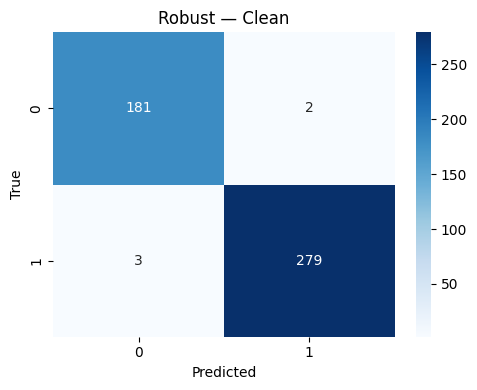


Robust — FGSM Accuracy: 0.9656


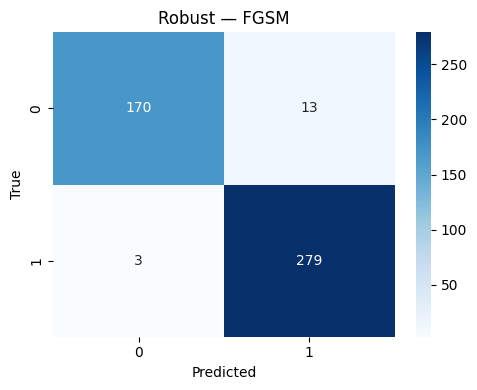

Robust — PGD Accuracy: 0.9075


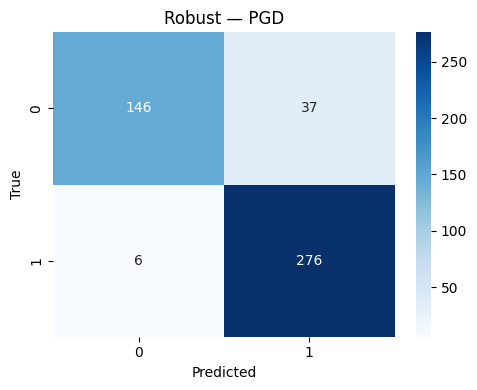

array([[146,  37],
       [  6, 276]])

In [ ]:
clean_metrics = evaluate(robust_model, test_loader, criterion, device, return_predictions=True)

print("=" * 60)
print("ROBUST — ЧИСТЫЕ ДАННЫЕ (после дообучения)")
print("=" * 60)
print(f"Accuracy:  {clean_metrics['accuracy']:.4f}")
print(f"Precision: {clean_metrics['precision']:.4f}")
print(f"Recall:    {clean_metrics['recall']:.4f}")
print(f"F1-Score:  {clean_metrics['f1']:.4f}")
plot_confusion_matrix(clean_metrics['preds'], clean_metrics['labels'],
                      'Robust — Clean', class_names)

# FGSM
fgsm_robust = torchattacks.FGSM(robust_model, eps=8/255)
robust_fgsm = evaluate_under_attack(
    robust_model, fgsm_robust, test_loader, device, return_predictions=True)
robust_fgsm_acc = robust_fgsm['accuracy']
print(f"\nRobust — FGSM Accuracy: {robust_fgsm_acc:.4f}")
plot_confusion_matrix(robust_fgsm['preds'], robust_fgsm['labels'],
                      'Robust — FGSM', class_names)

# PGD
pgd_robust = torchattacks.PGD(robust_model, eps=8/255, alpha=2/255, steps=10)
robust_pgd = evaluate_under_attack(
    robust_model, pgd_robust, test_loader, device, return_predictions=True)
robust_pgd_acc = robust_pgd['accuracy']
print(f"Robust — PGD Accuracy: {robust_pgd_acc:.4f}")
plot_confusion_matrix(robust_pgd['preds'], robust_pgd['labels'],
                      'Robust — PGD', class_names)

In [ ]:
def evaluate_on_rotations(model, dataset, angles, device, batch_size=32):
    """Оценка accuracy на повёрнутых изображениях (без ресайза, только поворот)."""
    model.eval()
    base_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    base_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for angle in angles:
        correct = 0
        total = 0
        for images, labels in loader:
            # денормализуем -> поворот -> нормализуем
            images = images * base_std + base_mean
            images = torch.clamp(images, 0, 1)
            images = torch.stack([TF.rotate(img, angle) for img in images])
            images = (images - base_mean) / base_std
            images, labels = images.to(device), labels.to(device)
            with torch.no_grad():
                outputs = model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        results[angle] = correct / total
    return results


def evaluate_on_noise(model, dataset, stds, device, batch_size=32):
    """Шум добавляем в ненормализованном пространстве, как и при обучении."""
    model.eval()
    base_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    base_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    results = {}
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for std in stds:
        correct = 0
        total = 0
        for images, labels in loader:
            images = images * base_std + base_mean
            images = torch.clamp(images + torch.randn_like(images) * std, 0, 1)
            images = (images - base_mean) / base_std
            images, labels = images.to(device), labels.to(device)
            with torch.no_grad():
                outputs = model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        results[std] = correct / total
    return results


angles = [-30, -15, 15, 30]
noise_stds = [0.05, 0.1, 0.15]

print("=" * 60)
print("УСТОЙЧИВОСТЬ К ПОВОРОТАМ")
print("=" * 60)
baseline_rot = evaluate_on_rotations(baseline_model, test_dataset, angles, device)
robust_rot = evaluate_on_rotations(robust_model, test_dataset, angles, device)
for a in angles:
    print(f"  angle={a:>3}°: baseline={baseline_rot[a]:.4f}, robust={robust_rot[a]:.4f}")

print("\n" + "=" * 60)
print("УСТОЙЧИВОСТЬ К ГАУССОВСКОМУ ШУМУ")
print("=" * 60)
baseline_noise = evaluate_on_noise(baseline_model, test_dataset, noise_stds, device)
robust_noise = evaluate_on_noise(robust_model, test_dataset, noise_stds, device)
for s in noise_stds:
    print(f"  std={s:.2f}: baseline={baseline_noise[s]:.4f}, robust={robust_noise[s]:.4f}")

УСТОЙЧИВОСТЬ К ПОВОРОТАМ
  angle=-30°: baseline=0.6688, robust=0.9505
  angle=-15°: baseline=0.8860, robust=0.9656
  angle= 15°: baseline=0.9548, robust=0.9785
  angle= 30°: baseline=0.7914, robust=0.9677

УСТОЙЧИВОСТЬ К ГАУССОВСКОМУ ШУМУ
  std=0.05: baseline=0.9570, robust=0.9892
  std=0.10: baseline=0.6516, robust=0.9914
  std=0.15: baseline=0.6065, robust=0.9914


In [ ]:
print("=" * 78)
print("СРАВНЕНИЕ УСТОЙЧИВОСТИ")
print("=" * 78)
header = f"{'Model':<12} {'Clean':<9} {'FGSM':<9} {'PGD':<9} {'Rot-30°':<9} {'Noise 0.1':<9}"
print(header)
print("-" * 78)
print(f"{'Baseline':<12} "
      f"{test_metrics_baseline['accuracy']:<9.4f} "
      f"{baseline_fgsm_acc:<9.4f} "
      f"{baseline_pgd_acc:<9.4f} "
      f"{baseline_rot[-30]:<9.4f} "
      f"{baseline_noise[0.1]:<9.4f}")
print(f"{'Robust':<12} "
      f"{clean_metrics['accuracy']:<9.4f} "
      f"{robust_fgsm_acc:<9.4f} "
      f"{robust_pgd_acc:<9.4f} "
      f"{robust_rot[15]:<9.4f} "
      f"{robust_noise[0.1]:<9.4f}")

СРАВНЕНИЕ УСТОЙЧИВОСТИ
Model        Clean     FGSM      PGD       Rot-30°   Noise 0.1
------------------------------------------------------------------------------
Baseline     0.9785    0.6065    0.2882    0.6688    0.6516   
Robust       0.9892    0.9656    0.9075    0.9785    0.9914   
